Importamos las librerias necesarias

In [1]:
# Importamos as bibliotecas necessárias
import pandas as pd

import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import precision_score, recall_score, confusion_matrix

from imblearn.over_sampling import SMOTE

import seaborn as sns

import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, auc

Importamos los datos dados


In [2]:
# Importamos los datos 
df = pd.read_stata("Base_deficit_y_muertos_112017_conesposos.dta")
df.head(10)

,unhhid,cunicah,codent01,subhog_01,acthog,codent03,subhog_03,np,subhog_12,subhog_15,...,c19_12_d,e1b_12_d,c69a_12_d,c70_12_d,c50b_12_d,age_12_cat,tiempo_cancer,c12_12_menos10_d,frail_index,quant
0,1.0,1.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010",31.NP=010 Deceased,...,0.0,1.0,1.0,0.0,1.0,>=50,NaN,0.0,0.400000,3.0
1,1.0,1.0,Spouse of selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Spouse of selected person in 2001,"01.No change, HH contains NP=010",20,"01.No change, HH contains NP=010",12.New HH contains NP=020,...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.028571,1.0
2,2.0,2.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,0.0,>=50,NaN,0.0,0.200000,2.0
3,2.0,2.0,Spouse of selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Spouse of selected person in 2001,"01.No change, HH contains NP=010",20,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,NaN,NaN,NaN,NaN,>=50,NaN,0.0,NaN,NaN
4,3.0,3.0,Selected person,00.Baseline HH,"Neither separation nor death, new spouse",Selected person in 2001,11.New HH contains NP=010,10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.114286,1.0
5,4.0,4.0,Spouse of selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Spouse of selected person in 2001,"01.No change, HH contains NP=010",20,12.New HH contains NP=020,12.New HH contains NP=020,...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.228571,3.0
6,5.0,5.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.228571,3.0
7,6.0,6.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,1.0,1.0,0.0,0.0,>=50,NaN,0.0,NaN,NaN
8,8.0,8.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,0.0,>=50,NaN,0.0,0.200000,2.0
9,9.0,9.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.142857,2.0


Renombramos varias de las columnas para facilitar su lectura y comprensión 

In [3]:
# Renombramos las columnas para que sean más fáciles de usar 
df = df.rename(columns= {
    "h13_12_d_2" : "Dress", "h5_12_d_2" : "In_out_chair", "h15d_12_d" : "Walk", 
    "h17d_12_d" : "Eat", "h16d_12_d" : "Groom", "h19d_12_d" : "Toilet", "h7_12_d_2": "Stairs",
    "h11_12_d_2" : "Lift", "h27c_12_d_2" : "Shop", "h26c_12_d_2" : "Meals", "h28c_12_d_2" : "Meds", 
    "h29c_12_d_2" : "Finance", "c64_12_d" : "Lost_weight", "c1_12_d" : "Health", "c2a_12_d" : "H_change",
    "c73_12_d" : "Bed", "c49_8_12_d" : "Tired", "h3_12_d_2" : "Walk_out", "c49_2_12_d" : "Effort", 
    "c49_1_12_d" : "Depressed", "c49_4_12_d" : "No_happy", "c49_5_12_d" : "Lone", "c49_9_12_d" : "No_Energy",
    "c4_12_d" : "High_BP", "c22a_12_d" : "Heart_attack", "c25b_12_d" : "CHF", "c26_12_d" : "Stroke",
    "c12_12_menos10_d" : "Cancer", "c6_12_d" : "Diabetes", "c32_12_d" : "Arthritis", "c19_12_d" : "CLD", 
    "e1b_12_d" : "Memory", "c69a_12_d" : "Grip", "fallecido_15" : "Dead", "c70_12_d" : "Anorexia", 
    "c50b_12_d" : "Excercise"})
df.head(10)

,unhhid,cunicah,codent01,subhog_01,acthog,codent03,subhog_03,np,subhog_12,subhog_15,...,CLD,Memory,Grip,Anorexia,Excercise,age_12_cat,tiempo_cancer,Cancer,frail_index,quant
0,1.0,1.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010",31.NP=010 Deceased,...,0.0,1.0,1.0,0.0,1.0,>=50,NaN,0.0,0.400000,3.0
1,1.0,1.0,Spouse of selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Spouse of selected person in 2001,"01.No change, HH contains NP=010",20,"01.No change, HH contains NP=010",12.New HH contains NP=020,...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.028571,1.0
2,2.0,2.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,0.0,>=50,NaN,0.0,0.200000,2.0
3,2.0,2.0,Spouse of selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Spouse of selected person in 2001,"01.No change, HH contains NP=010",20,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,NaN,NaN,NaN,NaN,>=50,NaN,0.0,NaN,NaN
4,3.0,3.0,Selected person,00.Baseline HH,"Neither separation nor death, new spouse",Selected person in 2001,11.New HH contains NP=010,10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.114286,1.0
5,4.0,4.0,Spouse of selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Spouse of selected person in 2001,"01.No change, HH contains NP=010",20,12.New HH contains NP=020,12.New HH contains NP=020,...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.228571,3.0
6,5.0,5.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.228571,3.0
7,6.0,6.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,1.0,1.0,0.0,0.0,>=50,NaN,0.0,NaN,NaN
8,8.0,8.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,0.0,>=50,NaN,0.0,0.200000,2.0
9,9.0,9.0,Selected person,00.Baseline HH,"Neither separation nor death, no new spouse",Selected person in 2001,"01.No change, HH contains NP=010",10,"01.No change, HH contains NP=010","01.No change, HH contains NP=010",...,0.0,0.0,0.0,0.0,1.0,>=50,NaN,0.0,0.142857,2.0


Creamos un dataframe nuevo con las columnas que nos interesan para hacer nuestro modelo, incluyendo el output y los inputs

In [4]:
# Creamos un dataframe nuevo con las columnas que usaremos para output e input
df_new = df[["Dress", "In_out_chair", "Walk", "Eat", "Groom", "Toilet", "Stairs", "Lift", "Shop",
        "Meals", "Meds", "Finance", "Lost_weight", "Health", "H_change", "Bed", "Tired", "Walk_out",
        "Effort", "Depressed", "No_happy", "Lone", "No_Energy", "High_BP", "Heart_attack", "CHF", 
        "Stroke", "Cancer", "Diabetes", "Arthritis", "CLD", "Memory", "Grip", "Anorexia", "Excercise", "Dead"]]
df_new.head(10)

,Dress,In_out_chair,Walk,Eat,Groom,Toilet,Stairs,Lift,Shop,Meals,...,Stroke,Cancer,Diabetes,Arthritis,CLD,Memory,Grip,Anorexia,Excercise,Dead
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,NaN,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
7,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


Cada una de nuestras variables indican: dificultad (valor 1) o no (valor cero), para:

Vestirse, levantarse de una silla, caminar, comer, arreglarse, ir al baño,
levantar cosas pesadas, hacer las compras, cocinar sus alimentos, tomar sus
medicamentos, manejar sus finanzas, así como pérdida de peso inexplicable,
problemas de salud, cambios de salud, dificultad para levantarse de la cama,
sentirse cansado, dificultad para caminar, sentir que todo es un esfuerzo,
estar o no deprimido, ser infeliz, sentirse solo, sentirse sin energía, tener
desde el último seguimiento presión arterial alta, ataque cardíaco, falla
crónica del corazón, embolia, cáncer, diabetes, artritis, problemas
pulmonares, fallas de memoria, dificultad para tomar objetos, si hay reporte
de muerte entre el 2012 y 2015, tener anorexia y tener dificultad para
ejercitarse. 

De este nuevo dataframe limpiamos los valores faltantes 

In [5]:
# Eliminamos las filas con valores nulos 
df_new = df_new.dropna()
df_new.head(10)

,Dress,In_out_chair,Walk,Eat,Groom,Toilet,Stairs,Lift,Shop,Meals,...,Stroke,Cancer,Diabetes,Arthritis,CLD,Memory,Grip,Anorexia,Excercise,Dead
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
12,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Seleccionamos las variables que ocuparemos como inputs y el output

In [6]:
# Seleccionamos las variables que vamos a usar de inputs y el output que es la variable "Dead"
X_input = df_new[["Dress", "In_out_chair", "Walk", "Eat", "Groom", "Toilet", "Stairs", "Lift", "Shop",
        "Meals", "Meds", "Finance", "Lost_weight", "Health", "H_change", "Bed", "Tired", "Walk_out",
        "Effort", "Depressed", "No_happy", "Lone", "No_Energy", "High_BP", "Heart_attack", "CHF", 
        "Stroke", "Cancer", "Diabetes", "Arthritis", "CLD", "Memory", "Grip", "Anorexia", "Excercise"]]
y = df_new["Dead"]


Veamos nuestros inputs

In [7]:
# Visualizamos la variable X_input para asegurarnos de no necesitar hacer un escalamiento de los datos
X_input.head(10)

,Dress,In_out_chair,Walk,Eat,Groom,Toilet,Stairs,Lift,Shop,Meals,...,CHF,Stroke,Cancer,Diabetes,Arthritis,CLD,Memory,Grip,Anorexia,Excercise
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
12,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


Veamos el input de cada observación

In [8]:
# Ahora veamos y 
y.head(10)

0     1.0
1     0.0
2     0.0
4     0.0
5     0.0
6     0.0
8     0.0
9     0.0
11    0.0
12    0.0
Name: Dead, dtype: float32

Dividimos el conjunto de datos en entrenamiento y prueba para el modelo 

In [9]:
# Dividimos los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_input, y, test_size=0.20, random_state=42)



Ajustamos el modelo knn con los diferentes modelos de k y obtenemos la precisión para cada k 

In [10]:
# Ajustamos el modelo KNN con los datos de entrenamiento y variaremos k 
k_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
for k in k_values:
    knn_normal = KNeighborsClassifier(n_neighbors = k)
    knn_normal.fit(X_train, y_train)
    y_pred = knn_normal.predict(X_test)
    precision = precision_score(y_test, y_pred)
    print(f"Precisión del modelo con k={k}: {precision:.4f}")


Precisión del modelo con k=1: 0.2449
Precisión del modelo con k=2: 0.5385
Precisión del modelo con k=3: 0.4231
Precisión del modelo con k=4: 0.7143
Precisión del modelo con k=5: 0.5625
Precisión del modelo con k=6: 0.7143
Precisión del modelo con k=7: 0.6154
Precisión del modelo con k=8: 0.5000
Precisión del modelo con k=9: 0.7500
Precisión del modelo con k=10: 1.0000
Precisión del modelo con k=11: 0.8000
Precisión del modelo con k=12: 1.0000


Hacemos lo mismo pero ahora para la sensitividad

In [80]:
# Ahora hacemos lo mismo que anteriormente pero para la sensitividad
for k in k_values:
    knn_normal = KNeighborsClassifier(n_neighbors = k)
    knn_normal.fit(X_train, y_train)
    y_pred = knn_normal.predict(X_test)
    recall = recall_score(y_test, y_pred)
    print(f"Sensitividad del modelo con k={k}: {recall:.4f}")

Sensitividad del modelo con k=1: 0.2000
Sensitividad del modelo con k=2: 0.0583
Sensitividad del modelo con k=3: 0.0917
Sensitividad del modelo con k=4: 0.0417
Sensitividad del modelo con k=5: 0.0750
Sensitividad del modelo con k=6: 0.0417
Sensitividad del modelo con k=7: 0.0667
Sensitividad del modelo con k=8: 0.0167
Sensitividad del modelo con k=9: 0.0500
Sensitividad del modelo con k=10: 0.0333
Sensitividad del modelo con k=11: 0.0333
Sensitividad del modelo con k=12: 0.0333


Al obtener estos resultados podemos observar que para algunos valores de k la precisión es excelnte, sin embargo la sensitividad más alta apenas llega a 20%. Esto ocurre por el desbalanceo en el conjunto de datos de salida, pues tenemos pocas observaciones con el marcador 1 a comparación del marcador 0

Solo para comprobar un poco lo que ya veniamos viendo, obtengamos las matrices de confusión 

In [81]:
# Como los datos estan desbalanceados, vamos a ver la matriz de confusión para ver cuántos casos positivos y negativos se predicen correctamente
for k in k_values:
    knn_normal = KNeighborsClassifier(n_neighbors = k)
    knn_normal.fit(X_train, y_train)
    y_pred = knn_normal.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print(f"Matriz de confusión del modelo con k={k}:\n{cm}\n")

Matriz de confusión del modelo con k=1:
[[2003   74]
 [  96   24]]

Matriz de confusión del modelo con k=2:
[[2071    6]
 [ 113    7]]

Matriz de confusión del modelo con k=3:
[[2062   15]
 [ 109   11]]

Matriz de confusión del modelo con k=4:
[[2075    2]
 [ 115    5]]

Matriz de confusión del modelo con k=5:
[[2070    7]
 [ 111    9]]

Matriz de confusión del modelo con k=6:
[[2075    2]
 [ 115    5]]

Matriz de confusión del modelo con k=7:
[[2072    5]
 [ 112    8]]

Matriz de confusión del modelo con k=8:
[[2075    2]
 [ 118    2]]

Matriz de confusión del modelo con k=9:
[[2075    2]
 [ 114    6]]

Matriz de confusión del modelo con k=10:
[[2077    0]
 [ 116    4]]

Matriz de confusión del modelo con k=11:
[[2076    1]
 [ 116    4]]

Matriz de confusión del modelo con k=12:
[[2077    0]
 [ 116    4]]



Curva de ROC

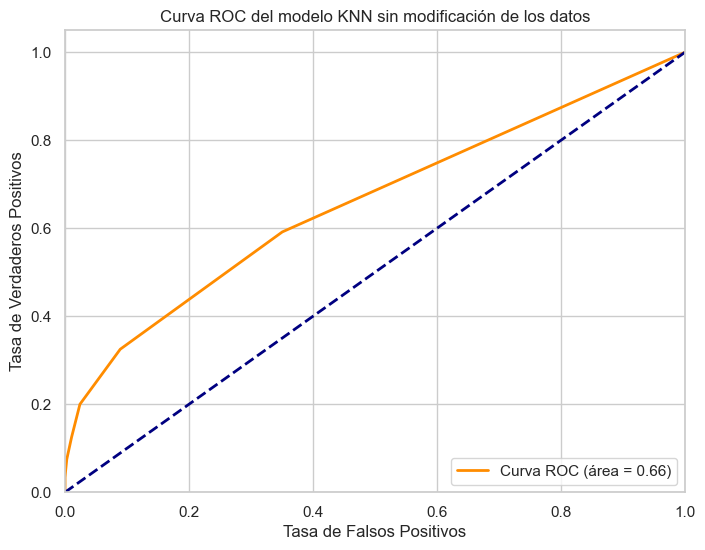

In [96]:
# Obtengamos la grafica de ROC para ver el desempeño del modelo
# Calculamos las probabilidades de predicción
probabilidades = knn_normal.predict_proba(X_test)[:, 1]
# Calculamos los puntos de la curva ROC
fpr, tpr, _ = roc_curve(y_test, probabilidades)
roc_auc = auc(fpr, tpr)
# Graficamos la curva ROC
sns.set(style = "whitegrid")
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color = "darkorange", lw = 2, label = f"Curva ROC (área = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color = "navy", lw = 2, linestyle = "--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC del modelo KNN sin modificación de los datos")
plt.legend(loc = "lower right")
plt.show()


Observemos que la curva de ROC está muy lejos de ser perfecta para poder decir que el modelo clasifica de manera correcta, confirmando lo que ya númericamente habíamos calculado

Habiendo visto esto podemos observar que en general nuestro modelo no es ni mucho menos preciso, pues se clasifican mal para cada k 

Por esta razón, primero probemos una estrategia de modificación del umbral de votación para ir obteniendo proporciones de vecinos que votan por la clase minoritaria para ir variando los pesos, variando el umbral para cada valor de k.

In [83]:
# Calculamos la sensitividad del modelo variando el umbral de decisión para ver si mejora la sensitividad del modelo
for k in k_values:
    knn_umbral = KNeighborsClassifier(n_neighbors = k)
    knn_umbral.fit(X_train, y_train)
    probabilidades1 = knn_umbral.predict_proba(X_test)[:, 1]
    # Variamos el umbral para ver si mejora la sensitividad del modelo
    for umbral_personalizado in [0.20, 0.25, 0.30, 0.35, 0.40]:
        predicciones_sensibles = (probabilidades1 >= umbral_personalizado).astype(int)
        recall = recall_score(y_test, predicciones_sensibles)
        print(f"Sensitividad del modelo con k={k} y umbral={umbral_personalizado}: {recall:.4f}")
        

Sensitividad del modelo con k=1 y umbral=0.2: 0.2000
Sensitividad del modelo con k=1 y umbral=0.25: 0.2000
Sensitividad del modelo con k=1 y umbral=0.3: 0.2000
Sensitividad del modelo con k=1 y umbral=0.35: 0.2000
Sensitividad del modelo con k=1 y umbral=0.4: 0.2000
Sensitividad del modelo con k=2 y umbral=0.2: 0.3000
Sensitividad del modelo con k=2 y umbral=0.25: 0.3000
Sensitividad del modelo con k=2 y umbral=0.3: 0.3000
Sensitividad del modelo con k=2 y umbral=0.35: 0.3000
Sensitividad del modelo con k=2 y umbral=0.4: 0.3000
Sensitividad del modelo con k=3 y umbral=0.2: 0.3000
Sensitividad del modelo con k=3 y umbral=0.25: 0.3000
Sensitividad del modelo con k=3 y umbral=0.3: 0.3000
Sensitividad del modelo con k=3 y umbral=0.35: 0.0917
Sensitividad del modelo con k=3 y umbral=0.4: 0.0917
Sensitividad del modelo con k=4 y umbral=0.2: 0.3167
Sensitividad del modelo con k=4 y umbral=0.25: 0.3167
Sensitividad del modelo con k=4 y umbral=0.3: 0.1333
Sensitividad del modelo con k=4 y umbra

Con esto podemos ver que la sensitividad para varias combinaciones de k y umbral sube, sin embargo sigue sin ser muy grande, siendo el valor mas grande: 41.67%

Veamos ahora que pasa con la precisión 

In [85]:
# Probemos ahora para la precision 
for k in k_values:
    knn_umbral = KNeighborsClassifier(n_neighbors = k)
    knn_umbral.fit(X_train, y_train)
    probabilidades2 = knn_umbral.predict_proba(X_test)[:, 1]
    # Variamos el umbral para ver si mejora la precisión del modelo
    for umbral_personalizado in [0.20, 0.25, 0.30, 0.35, 0.40]:
        predicciones_sensibles = (probabilidades2 >= umbral_personalizado).astype(int)
        precision_2 = precision_score(y_test, predicciones_sensibles)
        print(f"Precisión del modelo con k={k} y umbral={umbral_personalizado}: {precision_2:.4f}")

Precisión del modelo con k=1 y umbral=0.2: 0.2449
Precisión del modelo con k=1 y umbral=0.25: 0.2449
Precisión del modelo con k=1 y umbral=0.3: 0.2449
Precisión del modelo con k=1 y umbral=0.35: 0.2449
Precisión del modelo con k=1 y umbral=0.4: 0.2449
Precisión del modelo con k=2 y umbral=0.2: 0.1967
Precisión del modelo con k=2 y umbral=0.25: 0.1967
Precisión del modelo con k=2 y umbral=0.3: 0.1967
Precisión del modelo con k=2 y umbral=0.35: 0.1967
Precisión del modelo con k=2 y umbral=0.4: 0.1967
Precisión del modelo con k=3 y umbral=0.2: 0.1481
Precisión del modelo con k=3 y umbral=0.25: 0.1481
Precisión del modelo con k=3 y umbral=0.3: 0.1481
Precisión del modelo con k=3 y umbral=0.35: 0.4231
Precisión del modelo con k=3 y umbral=0.4: 0.4231
Precisión del modelo con k=4 y umbral=0.2: 0.1271
Precisión del modelo con k=4 y umbral=0.25: 0.1271
Precisión del modelo con k=4 y umbral=0.3: 0.3721
Precisión del modelo con k=4 y umbral=0.35: 0.3721
Precisión del modelo con k=4 y umbral=0.4:

Notemos que nuestra precisión bajo, siendo el mayor valor: 80%, sin embargo los valores mayores de la precisión con un k y umbral determinado no coinciden con los mayores valores en sensitividad, es por esto que no podemos encontrar una combinación "optima", dejandonos ver que una métrica sube, pero la otra baja

Por esta razón probemos con otro metódo de SMOTE, para ver si al generar datos sinteticos podemos balancear los datos y lograr obtener mejores métricas 

In [53]:
# Habiendo visto esto, apliquemos un oversampling para balancear los datos y veamos si mejora la sensitividad del modelo.
smote = SMOTE(random_state = 42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)


Entrenamos al modelo knn con estos nuevos datos balanceados y obtenemos la sensitividad

In [86]:
# Ahora volvamos a entrenar el modelo KNN con los datos balanceados y veamos si mejora la sensitividad del modelo.
for k in k_values:
    knn_smote = KNeighborsClassifier(n_neighbors = k)
    knn_smote.fit(X_train_resampled, y_train_resampled)
    y_pred = knn_smote.predict(X_test)
    recall = recall_score(y_test, y_pred)
    print(f"Sensitividad del modelo con k={k} después de oversampling: {recall:.4f}")
    


Sensitividad del modelo con k=1 después de oversampling: 0.3167
Sensitividad del modelo con k=2 después de oversampling: 0.3167
Sensitividad del modelo con k=3 después de oversampling: 0.4250
Sensitividad del modelo con k=4 después de oversampling: 0.4167
Sensitividad del modelo con k=5 después de oversampling: 0.5333
Sensitividad del modelo con k=6 después de oversampling: 0.5083
Sensitividad del modelo con k=7 después de oversampling: 0.5417
Sensitividad del modelo con k=8 después de oversampling: 0.4917
Sensitividad del modelo con k=9 después de oversampling: 0.5333
Sensitividad del modelo con k=10 después de oversampling: 0.5083
Sensitividad del modelo con k=11 después de oversampling: 0.5750
Sensitividad del modelo con k=12 después de oversampling: 0.5667


Notemos que la sensitividad sí aumento respecto a la medición inicial y a la técnica que usamos anteriormente, sin embargo no logramos un resultado tan bueno como nos gustaría

Veamos que pasa con la precisión 

In [87]:
# Veamos ahora la precisión del modelo después de aplicar oversampling
for k in k_values:
    knn_smote = KNeighborsClassifier(n_neighbors = k)
    knn_smote.fit(X_train_resampled, y_train_resampled)
    y_pred = knn_smote.predict(X_test)
    precision = precision_score(y_test, y_pred)
    print(f"Precisión del modelo con k={k} después de oversampling: {precision:.4f}")

Precisión del modelo con k=1 después de oversampling: 0.1467
Precisión del modelo con k=2 después de oversampling: 0.1617
Precisión del modelo con k=3 después de oversampling: 0.1321
Precisión del modelo con k=4 después de oversampling: 0.1397
Precisión del modelo con k=5 después de oversampling: 0.1283
Precisión del modelo con k=6 después de oversampling: 0.1338
Precisión del modelo con k=7 después de oversampling: 0.1178
Precisión del modelo con k=8 después de oversampling: 0.1132
Precisión del modelo con k=9 después de oversampling: 0.1046
Precisión del modelo con k=10 después de oversampling: 0.1050
Precisión del modelo con k=11 después de oversampling: 0.1044
Precisión del modelo con k=12 después de oversampling: 0.1079


Curva de ROC

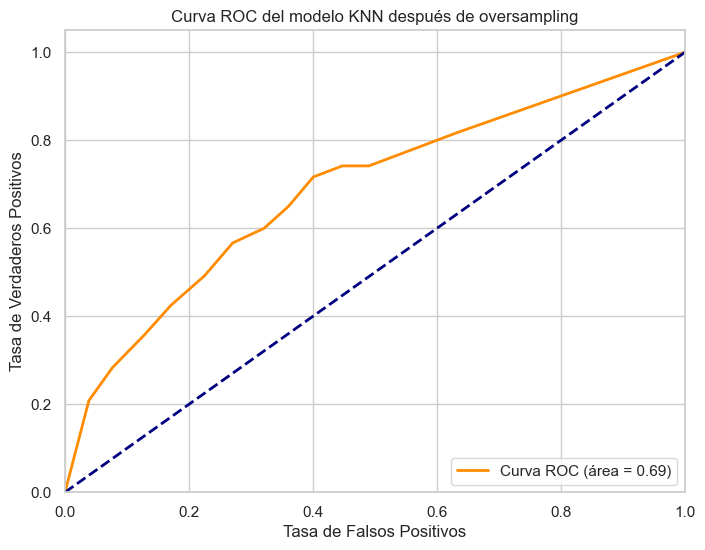

In [95]:
# Grafiquemos la curva ROC del modelo después de aplicar oversampling
# Calculamos las probabilidades de predicción
probabilidades_oversampling = knn_smote.predict_proba(X_test)[:, 1]
fpr_oversampling, tpr_oversampling, _ = roc_curve(y_test, probabilidades_oversampling)
roc_auc_oversampling = auc(fpr_oversampling, tpr_oversampling)
# Graficamos la curva ROC
sns.set(style = "whitegrid")
plt.figure(figsize=(8, 6))
plt.plot(fpr_oversampling, tpr_oversampling, color = "darkorange", lw = 2, label = f"Curva ROC (área = {roc_auc_oversampling:.2f})")
plt.plot([0, 1], [0, 1], color = "navy", lw = 2, linestyle = "--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC del modelo KNN después de oversampling")
plt.legend(loc = "lower right")
plt.show()


Como vimos, aunque balanceamos con datos sinteticos nuestro conjunto de datos, la precisión y la sensibilidad son demasiado bajas, confirmado por la curva de ROC (aunque subio el área respecto de las otras pruebas que hicimos), por ende probemos cambiando la métrica para medir distancia en knn que puede ser mejor para este caso de variables binarias para ambos casos (con oversampling y sin oversampling).


Precisión sin oversampling

In [89]:
# Probemos la metrica jaccard sin oversampling y calculemos la precisión del modelo
for k in k_values:
    knn_jaccard = KNeighborsClassifier(n_neighbors = k, metric = "jaccard")
    knn_jaccard.fit(X_train, y_train)
    y_pred = knn_jaccard.predict(X_test)
    precision = precision_score(y_test, y_pred)
    print(f"Métrica Jaccard del modelo con k={k} sin oversampling: {precision:.4f}")

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=1 sin oversampling: 0.2130


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=2 sin oversampling: 0.5000


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


...

Métrica Jaccard del modelo con k=10 sin oversampling: 1.0000


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=11 sin oversampling: 0.9167


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=12 sin oversampling: 1.0000


Notemos que con está nueva métrica logramos excelentes resultados de precisión, sin embargo esto tampoco es tan bueno, pues podríamos estar sufriendo de overfitting, da modo que revisemos que pasa con la sensitividad.

In [90]:
# Probemos la metrica jaccard sin oversampling y calculemos la sensitividad del modelo
for k in k_values:
    knn_jaccard = KNeighborsClassifier(n_neighbors = k, metric = "jaccard")
    knn_jaccard.fit(X_train, y_train)
    y_pred = knn_jaccard.predict(X_test)
    recall = recall_score(y_test, y_pred)
    print(f"Métrica Jaccard del modelo con k={k} sin oversampling: {recall:.4f}")

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=1 sin oversampling: 0.1917


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=2 sin oversampling: 0.0750


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


...

Métrica Jaccard del modelo con k=10 sin oversampling: 0.0667


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=11 sin oversampling: 0.0917


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=12 sin oversampling: 0.0583


Curva de ROC 

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


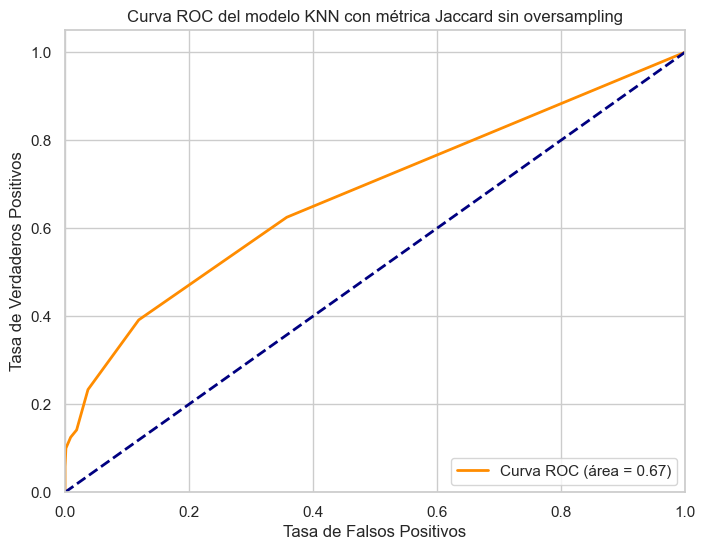

In [91]:
# Grafiquemos la curva de ROC del modelo con la metrica jaccard sin oversampling
# Calculamos las probabilidades de predicción
probabilidades_sin_oversampling = knn_jaccard.predict_proba(X_test)[:, 1]
fpr_sin_oversampling, tpr_sin_oversampling, _ = roc_curve(y_test, probabilidades_sin_oversampling)
roc_auc_sin_oversampling = auc(fpr_sin_oversampling, tpr_sin_oversampling)

# Graficamos la curva ROC
sns.set(style = "whitegrid")
plt.figure(figsize=(8, 6))
plt.plot(fpr_sin_oversampling, tpr_sin_oversampling, color = "darkorange", lw = 2, label = f"Curva ROC (área = {roc_auc_sin_oversampling:.2f})")
plt.plot([0, 1], [0, 1], color = "navy", lw = 2, linestyle = "--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC del modelo KNN con métrica Jaccard sin oversampling")
plt.legend(loc = "lower right")
plt.show()

Nuevamente volvemos a obtener lo mismo que ya veniamos visualizando: Una métrica sube mucho, mientras que la otra baja 

Así, probemos igual jaccard pero sobre los datos con oversampling y obtengamos la precisión

In [92]:
# Veamos ahora con oversampling y la metrica jaccard si mejora la precisión del modelo
for k in k_values:
    knn_jaccard_oversampled = KNeighborsClassifier(n_neighbors = k, metric = "jaccard")
    knn_jaccard_oversampled.fit(X_train_resampled, y_train_resampled)
    y_pred = knn_jaccard_oversampled.predict(X_test)
    precision = precision_score(y_test, y_pred)
    print(f"Métrica Jaccard del modelo con k={k} después de oversampling: {precision:.4f}")

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=1 después de oversampling: 0.1787


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=2 después de oversampling: 0.1930


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


...

Métrica Jaccard del modelo con k=10 después de oversampling: 0.1128


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=11 después de oversampling: 0.1040


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=12 después de oversampling: 0.1097


Desde aquí ya podemos ver que la precisión bajo muchisimo, siendo no un muy buen indicador de que nuestro modelo mejoró

In [93]:
# Veamos ahora con oversampling y la metrica jaccard si mejora la sensitividad del modelo
for k in k_values:
    knn_jaccard_oversampled = KNeighborsClassifier(n_neighbors = k, metric = "jaccard")
    knn_jaccard_oversampled.fit(X_train_resampled, y_train_resampled)
    y_pred = knn_jaccard_oversampled.predict(X_test)
    recall = recall_score(y_test, y_pred)
    print(f"Métrica Jaccard del modelo con k={k} después de oversampling: {recall:.4f}")

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=1 después de oversampling: 0.3083


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=2 después de oversampling: 0.2750


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


...

Métrica Jaccard del modelo con k=10 después de oversampling: 0.4917


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=11 después de oversampling: 0.5167


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Métrica Jaccard del modelo con k=12 después de oversampling: 0.5000


Curva de ROC


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


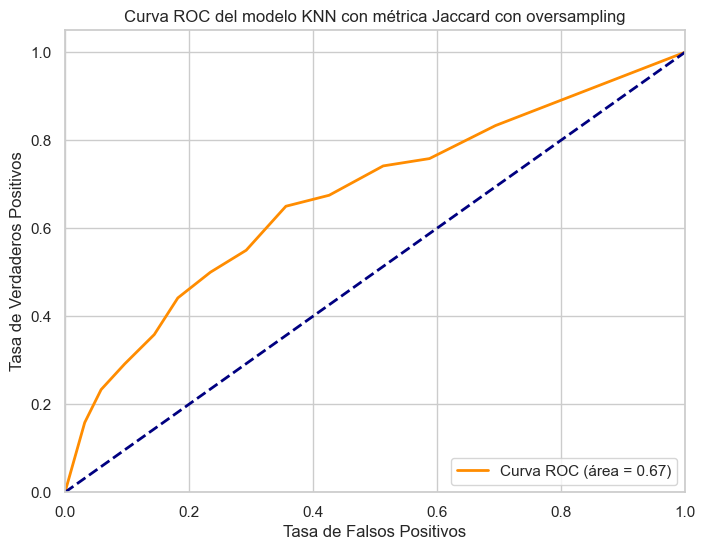

In [94]:
# Grafiquemos la curva de ROC del modelo con la metrica jaccard sin oversampling
# Calculamos las probabilidades de predicción
probabilidades_con_oversampling = knn_jaccard_oversampled.predict_proba(X_test)[:, 1]
fpr_con_oversampling, tpr_con_oversampling, _ = roc_curve(y_test, probabilidades_con_oversampling)
roc_auc_con_oversampling = auc(fpr_con_oversampling, tpr_con_oversampling)

# Graficamos la curva ROC
sns.set(style = "whitegrid")
plt.figure(figsize=(8, 6))
plt.plot(fpr_con_oversampling, tpr_con_oversampling, color = "darkorange", lw = 2, label = f"Curva ROC (área = {roc_auc_con_oversampling:.2f})")
plt.plot([0, 1], [0, 1], color = "navy", lw = 2, linestyle = "--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC del modelo KNN con métrica Jaccard con oversampling")
plt.legend(loc = "lower right")
plt.show()

Bien, el mismo efecto que anteriormente hemos visto, aunque está vez no subió tanto la sensitividad. Es por eso que hagamos una última prueba, combinando todo lo que hemos usado anteriormente para ver si tenemos mejores resultados 

Veamos la sensitividad

In [97]:
# Finalmente juntemos todo lo anterior y veamos si mejora la sensitividad del modelo con oversampling y la metrica jaccard
for k in k_values:
    knn_combinado = KNeighborsClassifier(n_neighbors = k, metric = "jaccard")
    knn_combinado.fit(X_train_resampled, y_train_resampled)
    probabilidades = knn_combinado.predict_proba(X_test)[:, 1]
    for umbral_personalizado in [0.20, 0.25, 0.30, 0.35, 0.40]:
        predicciones_sensibles = (probabilidades >= umbral_personalizado).astype(int)
        recall = recall_score(y_test, predicciones_sensibles)
        print(f"Sensitividad del modelo con k={k} y umbral={umbral_personalizado}: {recall:.4f}")

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Sensitividad del modelo con k=1 y umbral=0.2: 0.3083
Sensitividad del modelo con k=1 y umbral=0.25: 0.3083
Sensitividad del modelo con k=1 y umbral=0.3: 0.3083
Sensitividad del modelo con k=1 y umbral=0.35: 0.3083
Sensitividad del modelo con k=1 y umbral=0.4: 0.3083


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Sensitividad del modelo con k=2 y umbral=0.2: 0.3917
Sensitividad del modelo con k=2 y umbral=0.25: 0.3917
Sensitividad del modelo con k=2 y umbral=0.3: 0.3917
Sensitividad del modelo con k=2 y umbral=0.35: 0.3917
Sensitividad del modelo con k=2 y umbral=0.4: 0.3917


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


...

Sensitividad del modelo con k=10 y umbral=0.2: 0.7250
Sensitividad del modelo con k=10 y umbral=0.25: 0.6917
Sensitividad del modelo con k=10 y umbral=0.3: 0.6917
Sensitividad del modelo con k=10 y umbral=0.35: 0.6583
Sensitividad del modelo con k=10 y umbral=0.4: 0.6583


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Sensitividad del modelo con k=11 y umbral=0.2: 0.7083
Sensitividad del modelo con k=11 y umbral=0.25: 0.7083
Sensitividad del modelo con k=11 y umbral=0.3: 0.6750
Sensitividad del modelo con k=11 y umbral=0.35: 0.6750
Sensitividad del modelo con k=11 y umbral=0.4: 0.5917


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Sensitividad del modelo con k=12 y umbral=0.2: 0.7417
Sensitividad del modelo con k=12 y umbral=0.25: 0.7417
Sensitividad del modelo con k=12 y umbral=0.3: 0.6750
Sensitividad del modelo con k=12 y umbral=0.35: 0.6500
Sensitividad del modelo con k=12 y umbral=0.4: 0.6500


Ahora la precisión

In [98]:
# Finalmente juntemos todo lo anterior y veamos si mejora la precisión del modelo con oversampling y la metrica jaccard
for k in k_values:
    knn_combinado = KNeighborsClassifier(n_neighbors = k, metric = "jaccard")
    knn_combinado.fit(X_train_resampled, y_train_resampled)
    probabilidades = knn_combinado.predict_proba(X_test)[:, 1]
    for umbral_personalizado in [0.20, 0.25, 0.30, 0.35, 0.40]:
        predicciones_sensibles = (probabilidades >= umbral_personalizado).astype(int)
        precision_2 = precision_score(y_test, predicciones_sensibles)
        print(f"Precisión del modelo con k={k} y umbral={umbral_personalizado}: {precision_2:.4f}")

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Precisión del modelo con k=1 y umbral=0.2: 0.1787
Precisión del modelo con k=1 y umbral=0.25: 0.1787
Precisión del modelo con k=1 y umbral=0.3: 0.1787
Precisión del modelo con k=1 y umbral=0.35: 0.1787
Precisión del modelo con k=1 y umbral=0.4: 0.1787


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Precisión del modelo con k=2 y umbral=0.2: 0.1343
Precisión del modelo con k=2 y umbral=0.25: 0.1343
Precisión del modelo con k=2 y umbral=0.3: 0.1343
Precisión del modelo con k=2 y umbral=0.35: 0.1343
Precisión del modelo con k=2 y umbral=0.4: 0.1343


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


...

Precisión del modelo con k=10 y umbral=0.2: 0.0717
Precisión del modelo con k=10 y umbral=0.25: 0.0815
Precisión del modelo con k=10 y umbral=0.3: 0.0815
Precisión del modelo con k=10 y umbral=0.35: 0.0934
Precisión del modelo con k=10 y umbral=0.4: 0.0934


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Precisión del modelo con k=11 y umbral=0.2: 0.0786
Precisión del modelo con k=11 y umbral=0.25: 0.0786
Precisión del modelo con k=11 y umbral=0.3: 0.0881
Precisión del modelo con k=11 y umbral=0.35: 0.0881
Precisión del modelo con k=11 y umbral=0.4: 0.0938


c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Precisión del modelo con k=12 y umbral=0.2: 0.0771
Precisión del modelo con k=12 y umbral=0.25: 0.0771
Precisión del modelo con k=12 y umbral=0.3: 0.0839
Precisión del modelo con k=12 y umbral=0.35: 0.0954
Precisión del modelo con k=12 y umbral=0.4: 0.0954


Veamos por último la matriz de confusión 

In [99]:
# Obtengamos la matriz de confusión 
for k in k_values:
    knn_combinado = KNeighborsClassifier(n_neighbors = k, metric = "jaccard")
    knn_combinado.fit(X_train_resampled, y_train_resampled)
    y_pred = knn_combinado.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print(f"Matriz de confusión del modelo con k={k} después de oversampling:\n{cm}\n")

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Matriz de confusión del modelo con k=1 después de oversampling:
[[1907  170]
 [  83   37]]



c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Matriz de confusión del modelo con k=2 después de oversampling:
[[1939  138]
 [  87   33]]



c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


...

Matriz de confusión del modelo con k=10 después de oversampling:
[[1613  464]
 [  61   59]]



c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Matriz de confusión del modelo con k=11 después de oversampling:
[[1543  534]
 [  58   62]]



c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Matriz de confusión del modelo con k=12 después de oversampling:
[[1590  487]
 [  60   60]]



Curva de ROC 

c:\Users\aroja\anaconda3\Lib\site-packages\sklearn\metrics\pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


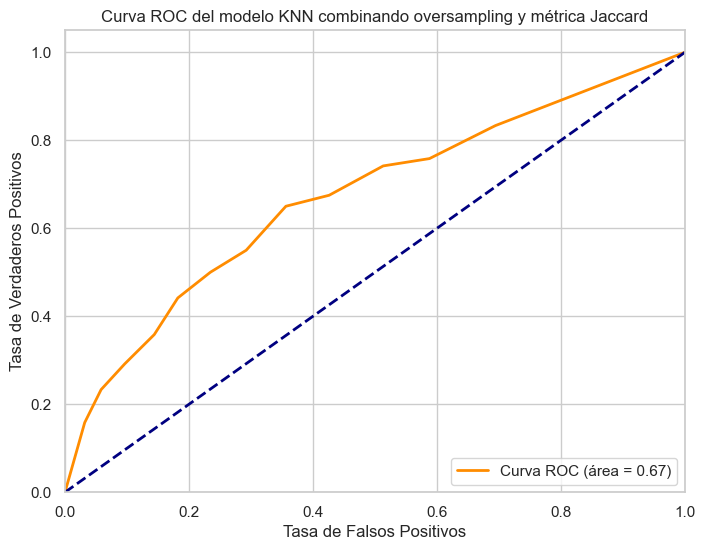

In [100]:
# Grafiquemos la curva de ROC del modelo con la metrica jaccard sin oversampling
# Calculamos las probabilidades de predicción
probabilidades_combinadas = knn_combinado.predict_proba(X_test)[:, 1]
fpr_combinado, tpr_combinado, _ = roc_curve(y_test, probabilidades_combinadas)
roc_auc_combinado = auc(fpr_combinado, tpr_combinado)

# Graficamos la curva ROC
sns.set(style = "whitegrid")
plt.figure(figsize=(8, 6))
plt.plot(fpr_combinado, tpr_combinado, color = "darkorange", lw = 2, label = f"Curva ROC (área = {roc_auc_combinado:.2f})")
plt.plot([0, 1], [0, 1], color = "navy", lw = 2, linestyle = "--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC del modelo KNN combinando oversampling y métrica Jaccard")
plt.legend(loc = "lower right")
plt.show()

Finalmente con esta última técnica podemos observar el mismo fénomeno, pues logramos subir la sensitividad lo más posible, pero la precisión quedo extremadamente baja, pudiendo confirmar de manera general que al tener datos desbalanceados como los que tenemos, al subir una métrica, otra baja, ya sea poco o drasticamente, por lo que quizá haría falta aplicar otro tipo de técnicas para poder obtener mejores resultados en ambas métricas 